In [1]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import plotly.express as px
import plotly.graph_objects as go
import statsmodels.api as sm

In [2]:
data = pd.read_csv('/Users/go202/Downloads/complete_index.csv')

In [3]:
data['log_speakers'] = np.log(data['n_speakers'])
data['log_models'] = np.log(data['models_n'])

/Users/go202/anaconda3/envs/eq_pap_1/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)
/Users/go202/anaconda3/envs/eq_pap_1/lib/python3.12/site-packages/pandas/core/arraylike.py:399: RuntimeWarning: divide by zero encountered in log
  result = getattr(ufunc, method)(*inputs, **kwargs)


In [4]:
data['models_n'] = pd.to_numeric(data['models_n'], errors='coerce')
# Ensure 'n_speakers' is numeric
data['n_speakers'] = pd.to_numeric(data['n_speakers'], errors='coerce')


if 'Enawené-Nawé' in data['language_name'].values:
    data.loc[data['language_name'] == 'Enawené-Nawé', 'models_n'] = 2

# Bin the data by 'Number of Speaker' using logarithmic bins
bins = [1, 100, 1000, 10000, 100000, 1000000, 10000000, 100000000, 1000000000, 10000000000]
labels = ["1-100", "100-1k", "1k-10k", "10k-100k", "100k-1M", "1M-10M", "10M-100M", "100M-1B", "1B+"]

# Create a new column 'bin' to categorize 'Number of Speaker' into bins
data['bin'] = pd.cut(data['n_speakers'], bins=bins, labels=labels, right=False, include_lowest=True)

# Group by bin and select the top 5 highest points within each bin based on 'Language Models'
# Drop rows where 'models_n' might be NaN after conversion
temp_data_for_top5 = data.dropna(subset=['models_n'])
top_5_per_bin = temp_data_for_top5.groupby('bin').apply(lambda x: x.nlargest(5, 'models_n')).reset_index(drop=True)

# Modify the number of speakers for English
if 'English' in data['language_name'].values:
    data.loc[data['language_name'] == 'English', 'n_speakers'] = 1_350_000_000

# Assign colors based on the conditions
# Using descriptive names that will be mapped to colorblind-friendly hex codes
def assign_color(row):
    # Handle potential NaN values in 'n_speakers' or 'models_n'
    if pd.isna(row['n_speakers']) or pd.isna(row['models_n']):
        return "Mid Tier Languages" # Default color for NaN values
    if row['n_speakers'] == 1:
        return 'Dead Languages'
    # For languages with more than 350,000 speakers, categorize based on models_n
    elif row['n_speakers'] > 350_000:
        if row['models_n'] < 35:
            return 'Underresourced Languages'
        # If models_n is 35 or more, it's considered 'Well resourced Languages'
        #elif row['models_n'] >= 35: # Using >= 35 to cover the gap and define 'Well resourced'
         #   return 'Well resourced Languages'
        else:
            return "Mid Tier Languages"
    return "Mid Tier Languages"

data['color'] = data.apply(assign_color, axis=1)

# Recalculate log values
# Filter out NaNs or non-positive values before taking log
data_for_log = data.dropna(subset=['n_speakers', 'models_n'])
data_for_log = data_for_log[(data_for_log['n_speakers'] > 0) & (data_for_log['models_n'] > 0)]

data['log_speakers'] = np.log(data_for_log['n_speakers'])
data['log_models'] = np.log(data_for_log['models_n'])

# Apply OLS regression
# Ensure X and Y are from the same filtered DataFrame
X = sm.add_constant(data_for_log['log_speakers'])
Y = data_for_log['log_models']

# Handle cases where Y or X might be empty after filtering
if not Y.empty and not X.empty:
    model = sm.OLS(Y, X).fit()
    # Predict on the original full data's log speakers, handling NaNs
    data['ols_fit'] = np.exp(model.predict(sm.add_constant(np.log(data['n_speakers'].replace(0, np.nan).dropna()))))
    # Align the ols_fit back to the original index
    data['ols_fit'] = data['ols_fit'].reindex(data.index)
else:
    print("Warning: Not enough data for OLS regression after filtering. OLS line will not be plotted.")
    data['ols_fit'] = np.nan # Set to NaN if OLS cannot be performed


# --- Create scatter plot ---
# Define a colorblind-friendly palette (Okabe-Ito palette)
colorblind_friendly_map = {
    'Dead Languages': '#000000',                # Teal/bluish-green for original 'green'
    'Underresourced Languages': '#D55E00',      # Vermillion/burnt orange for original 'red'
    'Well resourced Languages': '#009E73',      # Reddish-purple for original 'yellow'
    "Mid Tier Languages": '#0072B2' # Darker blue for original 'blue'
}

fig = px.scatter(
    data,
    x="n_speakers",
    y="models_n",
    hover_name="language_name",  # This will show the language name when hovering
    #title="Number of Speakers vs. Number of Models",
    labels={"n_speakers": "Number of Speakers (log scale)", "models_n": "Number of Models (log scale)"},
    log_x=True,
    log_y=True,
    size_max=2,
    color="color",
    opacity=0.8,
    color_discrete_map=colorblind_friendly_map
)

# Add top 5 points from each bin to the plot as red circles and set hover_name as 'name'
# Using the colorblind-friendly red/vermillion for these markers
fig.add_scatter(
    x=top_5_per_bin['n_speakers'],
    y=top_5_per_bin['models_n'],
    mode='markers',
    marker=dict(color='#009E73', size=15, symbol='circle'),
    name='Top 5 Languages per Speaker Bin',
    hovertext=top_5_per_bin['language_name']  # This ensures the language name appears on hover
)

# Add OLS Fit line
# Filter out NaN values from ols_fit before plotting
if 'ols_fit' in data.columns and not data['ols_fit'].isnull().all():
    # Sort by n_speakers for a smooth line
    data_sorted_for_ols_plot = data.dropna(subset=['n_speakers', 'ols_fit']).sort_values('n_speakers')
    fig.add_scatter(
        x=data_sorted_for_ols_plot['n_speakers'],
        y=data_sorted_for_ols_plot['ols_fit'],
        mode='lines',
        name='OLS Fit',
        line=dict(color='purple', width=2) # Customizing line color and width
    )

# The section for highlighting points where 'Language Models' > 150 has been removed.

# Update layout
fig.update_layout(
    legend=dict(
        orientation="h",
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1, 
        title_text =''
    ),
    template="plotly_white"
)

# Show the updated plot
fig.show()
#fig.write_image("number_of_speakers_vs_models_final.pdf")


/var/folders/hw/3z11r39j0gd4kgzxbjj6v8z80000gp/T/ipykernel_97437/1509960759.py:19: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  top_5_per_bin = temp_data_for_top5.groupby('bin').apply(lambda x: x.nlargest(5, 'models_n')).reset_index(drop=True)
/var/folders/hw/3z11r39j0gd4kgzxbjj6v8z80000gp/T/ipykernel_97437/1509960759.py:19: DeprecationWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  top_5_per_bin = temp_data_for_top5.groupby('bin').apply(lambda x: x.nlargest(5, 'models_n')).reset_index(drop=True)


In [5]:
world = gpd.read_file("/Users/go202/Downloads/ne_110m_admin_0_countries 2/ne_110m_admin_0_countries.shp")

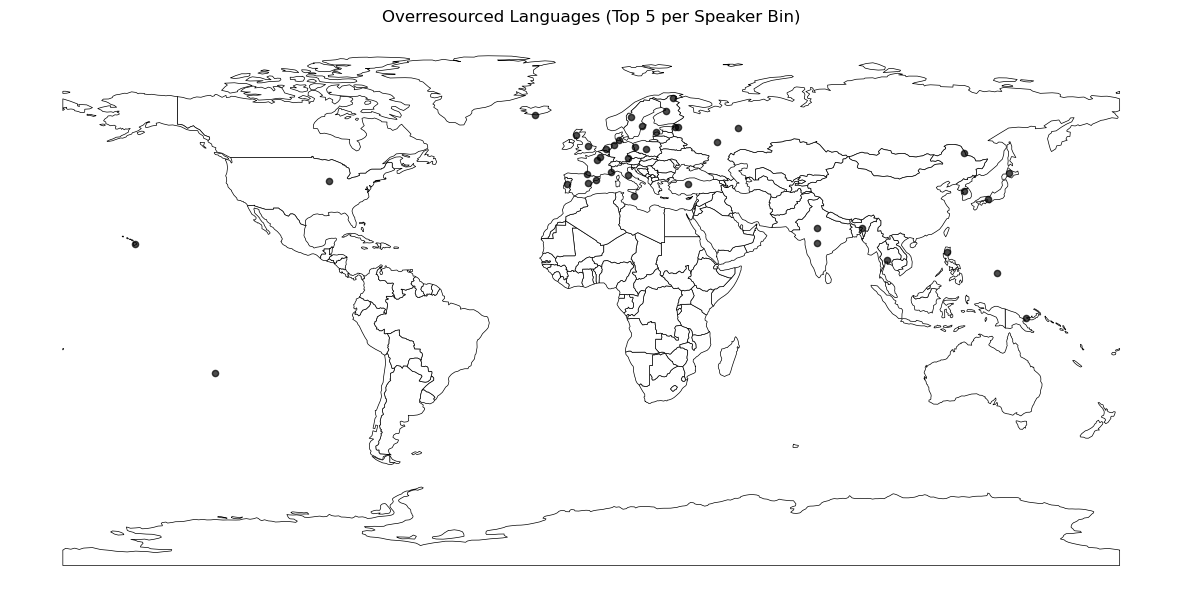

No data to plot for: Well Resourced Languages


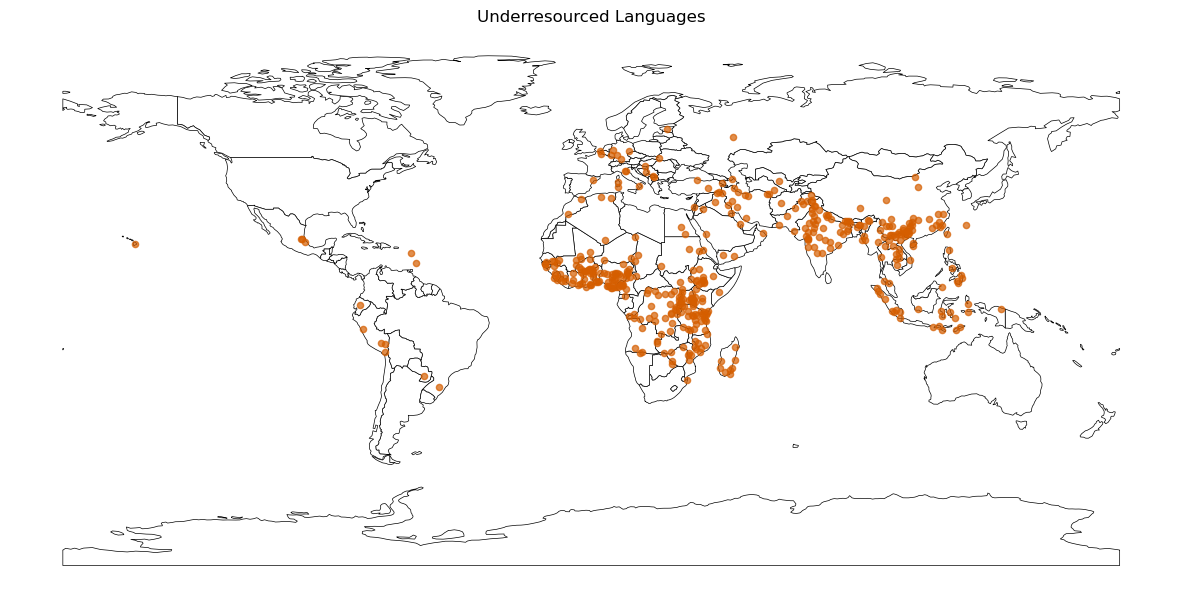

Figure saved to: underr.pdf


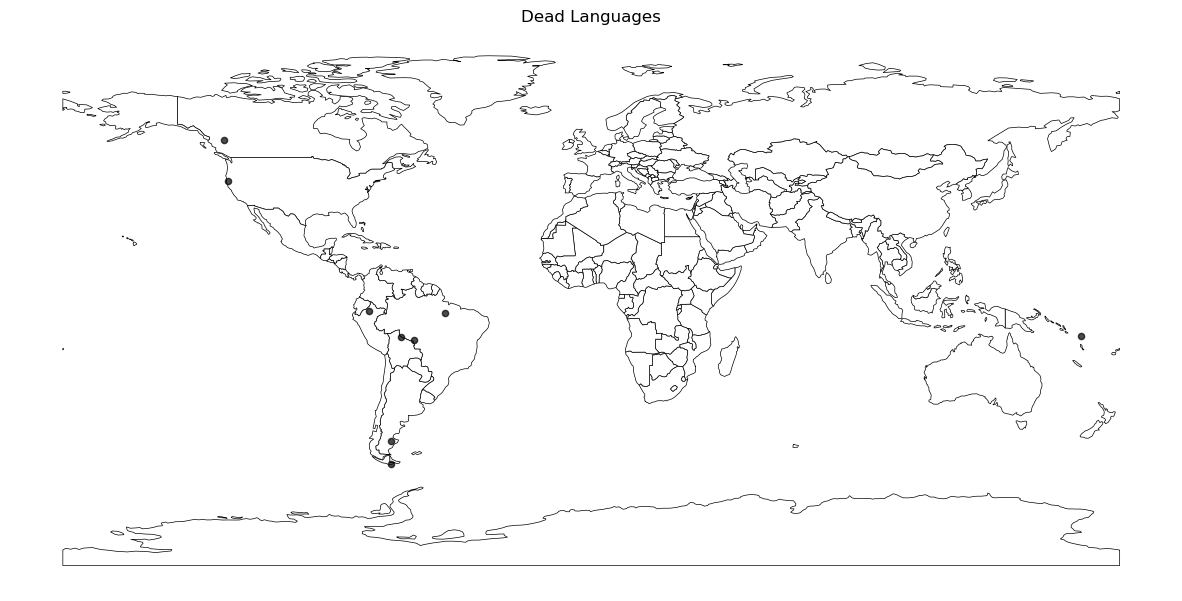

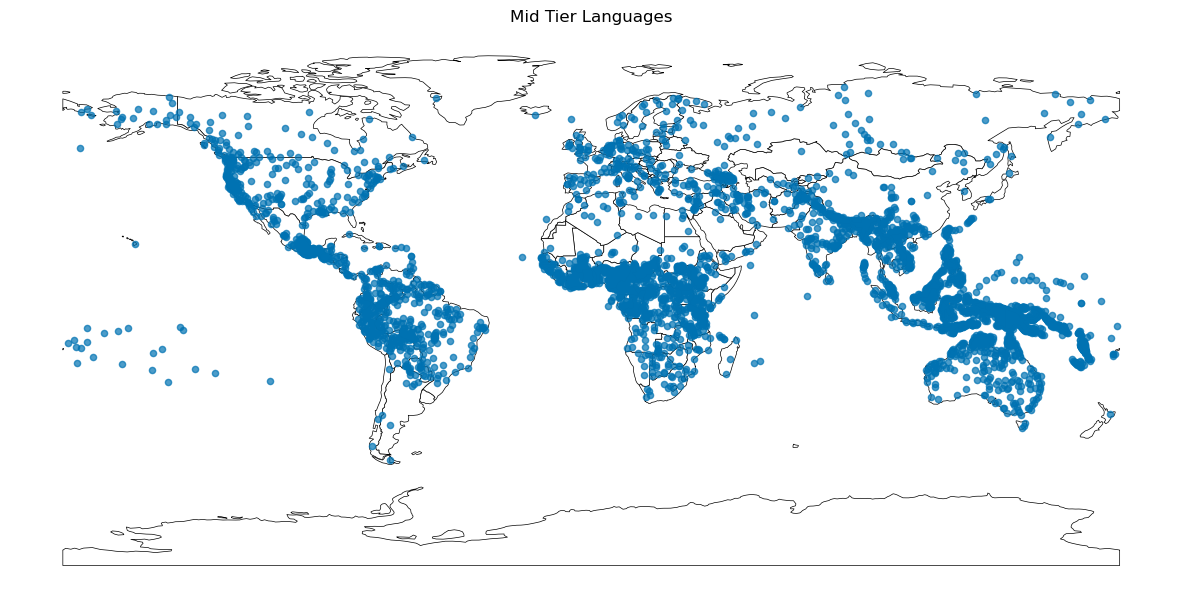

Figure saved to: mid_tier_languages_map.pdf


In [6]:
def plot_languages_on_map(data_to_plot, point_color, plot_title, filename=None, save_fig=True):
    """
    Plots a given GeoDataFrame of languages on a world map.

    Args:
        data_to_plot (pd.DataFrame): DataFrame containing 'latitude' and 'longitude'
                                     columns for the points to plot.
        point_color (str): Hex code or common color name for the points.
        plot_title (str): Title of the map.
        filename (str, optional): Filename to save the plot (e.g., 'my_map.pdf').
                                  Required if save_fig is True.
        save_fig (bool, optional): If True, saves the figure to the specified filename.
                                   Defaults to True.
    """
    if not data_to_plot.empty:
        gdf = gpd.GeoDataFrame(
            data_to_plot,
            geometry=gpd.points_from_xy(data_to_plot.longitude, data_to_plot.latitude)
        )

        fig, ax = plt.subplots(figsize=(15, 10))
        world.plot(ax=ax, color='white', edgecolor='black', linewidth=0.5)

        gdf.plot(
            ax=ax,
            color=point_color,
            markersize=20,
            alpha=0.7
        )

        ax.set_title(plot_title)
        ax.axis('off')
        plt.show() # Always show the plot

        if save_fig:
            if filename is None:
                print("Warning: save_fig is True but no filename provided. Figure will not be saved.")
            else:
                fig.savefig(filename, bbox_inches='tight')
                print(f"Figure saved to: {filename}")
        plt.close(fig) # Close the figure to free up memory

    else:
        print(f"No data to plot for: {plot_title}")



plot_languages_on_map(
    top_5_per_bin,
    'black',
    'Overresourced Languages (Top 5 per Speaker Bin)',
    'top_5_languages_map.pdf',
    save_fig=False 
)


well_resourced_languages = data[data['color'] == 'Well resourced Languages']
plot_languages_on_map(
    well_resourced_languages,
    '#009E73',
    'Well Resourced Languages', # Added plot_title argument
    'well_resourced.pdf',
    save_fig=False 
)


underresourced_languages = data[data['color'] == 'Underresourced Languages']
plot_languages_on_map(
    underresourced_languages,
    '#D55E00',
    'Underresourced Languages',
    'underr.pdf',
    save_fig=True 
)

dead_languages = data[data['color'] == 'Dead Languages']
plot_languages_on_map(
    dead_languages,
    '#000000',
    'Dead Languages',
    'dead_languages_map.pdf',
    save_fig=False 
)   

mid_tier_languages = data[data['color'] == 'Mid Tier Languages']
plot_languages_on_map(
    mid_tier_languages,
    '#0072B2',
    'Mid Tier Languages',
    'mid_tier_languages_map.pdf',
    save_fig=True 
)